# Blind Equalization with the Constant Modulus Algorithm (CMA)
**AVD612 course project — complete, self-contained notebook** (theory · library · tests · experiments · results · viva notes)

Run all cells top to bottom (~3 min). Figures are shown inline **and** saved to `figs/`. Every number quoted in the
summary is produced by the code below. Set `QUICK = True` in the setup cell for a fast smoke test (fewer Monte-Carlo runs).

| Section | Content |
|---|---|
| 1 | Theory: model, cost, $R_2$, gradient, ambiguities |
| 2 | Library: signals, CMA / LMS / DD-LMS / MMSE, metrics |
| 3 | Unit tests |
| 4 | Experiments E1–E10 (constellation, $h*w$, frequency response, learning curve, step size, BER, parameter studies, QAM + DD, LMS comparison) |
| 5 | Results summary (auto-generated numbers) |
| 6 | Viva notes, AI-usage note |

## 1. Theory

**Signal model.** $x[n]=\sum_{k=0}^{M-1}h_k s[n-k]+v[n]$, $v\sim\mathcal{CN}(0,\sigma^2)$, $\sigma^2=10^{-\mathrm{SNR}/10}$, $\|\mathbf h\|=1$, $\mathbb E|s|^2=1$.
Equalizer: $y[n]=\mathbf w^T\mathbf u[n]$, $\mathbf u[n]=[x[n],\dots,x[n-L+1]]^T$. Combined response $\mathbf c=\mathbf h*\mathbf w$;
ideal: $\mathbf c=g\,\delta[k-d]$. Residual ISI $=\dfrac{\sum_k|c_k|^2-\max_k|c_k|^2}{\max_k|c_k|^2}$.

**Cost.** $J(\mathbf w)=\mathbb E[(|y|^2-R_2)^2]$.

**Why $R_2=\mathbb E|s|^4/\mathbb E|s|^2$.** For an ideal output $y=gs$, $a=|g|^2$: $\partial J/\partial a=2\mathbb E[(a|s|^2-R_2)|s|^2]$. Requiring the unit-gain solution $a=1$ to be stationary gives $R_2=\mathbb E|s|^4/\mathbb E|s|^2$.

**Gradient.** Wirtinger calculus with $y=\mathbf w^T\mathbf u$: $\partial y/\partial\mathbf w^*=0$, $\partial y^*/\partial\mathbf w^*=\mathbf u^*$, so $\partial|y|^2/\partial\mathbf w^*=y\mathbf u^*$ and
$\nabla_{\mathbf w^*}J=2\,\mathbb E[(|y|^2-R_2)\,y\,\mathbf u^*]$. Dropping the expectation and absorbing the 2 into $\mu$:

$$\mathbf w[n+1]=\mathbf w[n]-\mu\,(|y[n]|^2-R_2)\,y[n]\,\mathbf u^*[n].$$

**Ambiguities.** $J(e^{j\theta}\mathbf w)=J(\mathbf w)$ ⇒ continuous **phase** ambiguity. I.i.d. symbols ⇒ any shift of $\mathbf c$ gives the same $J$ ⇒ **delay** ambiguity.
**Local minima / init.** $J$ is non-convex; centre-spike init gives $\mathbf c\approx\mathbf h$ with one dominant tap; $\mathbf w=\mathbf 0$ is a stationary point and never moves.
**Non-constant modulus.** At the ideal point $J_{\min}=R_2(R_2-1)$: 0 for QPSK, 0.422 for 16-QAM, 0.526 for 64-QAM ⇒ misadjustment; follow CMA with decision-directed LMS.

*Conventions:* $T$-spaced model, ideal timing; SNR $=E_s/N_0$; BER/SER measured on a fresh block with the filter frozen after pilot-aided delay/gain/phase resolution.

In [1]:
%matplotlib inline
import json, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from math import erfc, sqrt
warnings.filterwarnings("ignore")

QUICK = False          # True -> fewer Monte-Carlo runs (fast smoke test)
FIG, RES = Path("figs"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
SEED = 2026
NUM, JSON, TAB = {}, {}, {}

## 2. Library
### 2.1 Signals and channel

In [2]:
H_MILD = np.array([1, 0.4 + 0.2j, 0.2 - 0.1j])      # main channel from the brief
H_HARSH = np.array([1.0, 0.95])                      # near spectral null at f = 0.5


def normalize_channel(h):
    """Unit-energy channel so that SNR is defined w.r.t. unit-power symbols."""
    h = np.asarray(h, dtype=complex)
    return h / np.linalg.norm(h)


def constellation(name):
    """Unit average-power constellation (complex ndarray) for a modulation name."""
    name = name.upper()
    if name == "BPSK":
        pts = np.array([-1, 1], dtype=complex)
    elif name == "QPSK":
        pts = np.exp(1j * (np.pi / 4 + np.pi / 2 * np.arange(4)))
    elif name == "8-PSK":
        pts = np.exp(1j * 2 * np.pi * np.arange(8) / 8)
    elif name.endswith("QAM"):
        M = int(name.split("-")[0])
        k = int(np.sqrt(M))
        lev = np.arange(-(k - 1), k, 2)
        pts = (lev[:, None] + 1j * lev[None, :]).ravel()
    else:
        raise ValueError(name)
    return pts / np.sqrt(np.mean(np.abs(pts) ** 2))


def cm_constant(pts):
    """Godard dispersion constant R2 = E|s|^4 / E|s|^2 for equiprobable symbols."""
    a2 = np.abs(pts) ** 2
    return float(np.mean(a2 ** 2) / np.mean(a2))


def gen_symbols(mod, shape, rng):
    """i.i.d. equiprobable symbols of modulation ``mod`` with the given shape."""
    pts = constellation(mod)
    return pts[rng.integers(0, len(pts), size=shape)]


def apply_channel(s, h, snr_db, rng):
    """x[n] = sum_k h[k] s[n-k] + v[n],  v ~ CN(0, 10^(-snr/10)).

    ``s`` has shape (R, N); ``snr_db`` is a scalar or an (R,) array = Es/N0 for
    unit-power symbols (h is expected to be unit-energy).
    """
    s = np.atleast_2d(s)
    R, N = s.shape
    x = np.zeros((R, N), dtype=complex)
    for k, hk in enumerate(h):
        x[:, k:] += hk * s[:, : N - k]
    sig2 = 10.0 ** (-np.asarray(snr_db, dtype=float) / 10.0)
    sig2 = np.broadcast_to(sig2, (R,))[:, None]
    v = np.sqrt(sig2 / 2) * (rng.standard_normal((R, N)) + 1j * rng.standard_normal((R, N)))
    return x + v

### 2.2 Equalizers (CMA, LMS, DD-LMS, oracle MMSE) — vectorised over Monte-Carlo runs
Convention: $y[n]=\sum_i w_i x[n-i]$; all trainers take `x` of shape `(runs, N)` and loop over time only.

In [3]:
def _windows(x, L):
    xp = np.concatenate([np.zeros((x.shape[0], L - 1), complex), x], axis=1)
    return sliding_window_view(xp, L, axis=1)[:, :, ::-1]      # (R, N, L), newest first


def init_weights(R, L, init="center", rng=None, center=None):
    w = np.zeros((R, L), dtype=complex)
    c = L // 2 if center is None else center
    if init == "center":
        w[:, c] = 1.0
    elif init == "first":
        w[:, 0] = 1.0
    elif init == "random":
        w = rng.standard_normal((R, L)) + 1j * rng.standard_normal((R, L))
        w /= np.linalg.norm(w, axis=1, keepdims=True)
    elif init == "zero":
        pass                     # w = 0 is a stationary point of CMA: it never moves
    else:
        raise ValueError(init)
    return w


def cma_train(x, L, mu, R2, init="center", rng=None, snap_every=0, w0=None):
    """Godard p=2 CMA (CMA 2-2):  y=w^T u,  w <- w - mu (|y|^2-R2) y u*.

    Returns (y, w) or (y, w, snaps): a-priori outputs y (R,N), final weights
    (R,L) and optional weight snapshots every ``snap_every`` samples (R,S,L).
    """
    R, N = x.shape
    U = _windows(x, L)
    w = init_weights(R, L, init, rng) if w0 is None else w0.copy()
    y = np.empty((R, N), complex)
    snaps = []
    with np.errstate(all="ignore"):
        for n in range(N):
            u = U[:, n, :]
            yn = np.einsum("rl,rl->r", w, u)
            g = (np.abs(yn) ** 2 - R2) * yn
            w = w - mu * g[:, None] * np.conj(u)
            y[:, n] = yn
            if snap_every and (n + 1) % snap_every == 0:
                snaps.append(w.copy())
    return (y, w, np.stack(snaps, axis=1)) if snap_every else (y, w)


def lms_train(x, s, L, mu, delay, snap_every=0):
    """Data-aided complex LMS:  e = s[n-delay] - y,  w <- w + mu e u*."""
    R, N = x.shape
    U = _windows(x, L)
    d = np.concatenate([np.zeros((R, delay), complex), s], axis=1)[:, :N]
    w = init_weights(R, L, "center", center=min(delay, L - 1))   # same spike init as CMA
    y = np.empty((R, N), complex)
    snaps = []
    with np.errstate(all="ignore"):
        for n in range(N):
            u = U[:, n, :]
            yn = np.einsum("rl,rl->r", w, u)
            w = w + mu * (d[:, n] - yn)[:, None] * np.conj(u)
            y[:, n] = yn
            if snap_every and (n + 1) % snap_every == 0:
                snaps.append(w.copy())
    return (y, w, np.stack(snaps, axis=1)) if snap_every else (y, w)


def dd_lms_train(x, pts, L, mu, w0):
    """Decision-directed LMS (w0 must already have correct scale and phase)."""
    R, N = x.shape
    U = _windows(x, L)
    w = w0.copy()
    y = np.empty((R, N), complex)
    with np.errstate(all="ignore"):
        for n in range(N):
            u = U[:, n, :]
            yn = np.einsum("rl,rl->r", w, u)
            dec = pts[np.argmin(np.abs(yn[:, None] - pts[None, :]), axis=1)]
            w = w + mu * (dec - yn)[:, None] * np.conj(u)
            y[:, n] = yn
    return y, w


def apply_filter(x, w):
    """Apply fixed per-run filters: y[n] = sum_i w[r,i] x[r,n-i]."""
    R, N = x.shape
    y = np.zeros((R, N), complex)
    for i in range(w.shape[1]):
        y[:, i:] += w[:, i:i + 1] * x[:, : N - i]
    return y


def mmse_ls(x, s, L):
    """Oracle data-aided linear MMSE equalizer (sample Wiener / least squares).

    For each run, solves (U^H U) w = U^H s_d for every delay d in 0..L-1 and keeps
    the delay with smallest error.  Returns w (R,L) and chosen delay (R,).
    """
    R, N = x.shape
    U = _windows(x, L)
    W = np.zeros((R, L), complex)
    D = np.zeros(R, int)
    for r in range(R):
        Ur = U[r, L:]                                   # skip start-up transient
        A = Ur.conj().T @ Ur + 1e-9 * np.eye(L)
        best = np.inf
        for d in range(L):
            sd = s[r, L - d: N - d]
            b = Ur.conj().T @ sd
            w = np.linalg.solve(A, b)
            err = np.real(sd.conj() @ sd - b.conj() @ w)
            if err < best:
                best, W[r], D[r] = err, w, d
    return W, D

### 2.3 Metrics and ambiguity resolution

In [4]:
def qfunc(x):
    return 0.5 * np.vectorize(erfc)(np.asarray(x, dtype=float) / sqrt(2))


def combined_response(h, w):
    """c = h * w  (channel convolved with equalizer), shape (R, M+L-1)."""
    return np.stack([np.convolve(h, wr) for wr in np.atleast_2d(w)])


def residual_isi(c, db=False):
    """ISI = (sum|c|^2 - max|c|^2)/max|c|^2, per run."""
    p = np.abs(c) ** 2
    m = p.max(axis=1)
    isi = (p.sum(axis=1) - m) / m
    return 10 * np.log10(np.maximum(isi, 1e-12)) if db else isi


def align(y, s, max_delay, skip=50):
    """Resolve delay, scale and phase with known symbols (pilot-aided).

    y[n] ~ g s[n-d].  Per run choose d minimising ||y - g s_d||^2 with complex
    g = <s_d,y>/<s_d,s_d>.  Returns y/g, reference symbols aligned to y, d, g.
    """
    R, N = y.shape
    best = np.full(R, np.inf)
    d_best = np.zeros(R, int)
    g_best = np.ones(R, complex)
    yy = y[:, skip:]
    for d in range(max_delay + 1):
        sd = s[:, skip - d: N - d]
        g = np.sum(sd.conj() * yy, axis=1) / np.sum(np.abs(sd) ** 2, axis=1)
        err = np.sum(np.abs(yy - g[:, None] * sd) ** 2, axis=1)
        ok = (err < best) & np.isfinite(err)
        best[ok], d_best[ok], g_best[ok] = err[ok], d, g[ok]
    ya = y / np.where(np.abs(g_best) > 1e-12, g_best, 1)[:, None]
    ref = np.zeros_like(y)
    for r in range(R):
        d = d_best[r]
        ref[r, d:] = s[r, : N - d]
    return ya, ref, d_best, g_best


def hard_decision(y, pts):
    return pts[np.argmin(np.abs(y[..., None] - pts), axis=-1)]


def ber_qpsk(ya, ref, skip=50):
    """Gray-coded QPSK bit error rate from sign decisions on I and Q."""
    a, b = ya[:, skip:], ref[:, skip:]
    err = (np.sign(a.real) != np.sign(b.real)).sum(1) + (np.sign(a.imag) != np.sign(b.imag)).sum(1)
    return err / (2 * a.shape[1])


def ser(ya, ref, pts, skip=50):
    a, b = ya[:, skip:], ref[:, skip:]
    out = np.empty(a.shape[0])
    for r in range(a.shape[0]):
        out[r] = np.mean(np.abs(hard_decision(a[r], pts) - b[r]) > 1e-9)
    return out

## 3. Unit tests

In [5]:
def test_dispersion_constant():
    assert abs(cm_constant(constellation("QPSK")) - 1.0) < 1e-12        # constant modulus
    assert abs(cm_constant(constellation("16-QAM")) - 1.32) < 1e-9       # E|s|^4/E|s|^2 = 1.32
    assert cm_constant(constellation("64-QAM")) > 1.3


def test_constellations_unit_power():
    for m in ["BPSK", "QPSK", "8-PSK", "16-QAM", "64-QAM"]:
        assert abs(np.mean(np.abs(constellation(m)) ** 2) - 1) < 1e-12


def test_isi_metric():
    assert residual_isi(np.array([[0, 0, 2.0, 0, 0]])) [0] < 1e-12       # perfect spike
    assert abs(residual_isi(np.array([[1.0, 1.0]]))[0] - 1.0) < 1e-12      # two equal taps


def test_spike_init_is_stationary_for_clean_cm_signal():
    rng = np.random.default_rng(0)
    s = gen_symbols("QPSK", (1, 500), rng)
    y, w = cma_train(s, 7, 1e-2, 1.0)                                    # no channel -> already optimal
    assert np.allclose(w[0], np.eye(7)[3], atol=1e-9)


def test_zero_init_never_moves():
    rng = np.random.default_rng(1)
    x = gen_symbols("QPSK", (1, 300), rng)
    _, w = cma_train(x, 5, 1e-2, 1.0, init="zero")
    assert np.all(w == 0)


def test_cma_reduces_isi_and_has_phase_ambiguity():
    rng = np.random.default_rng(2)
    h = normalize_channel(H_MILD) * np.exp(1j * 0.7)
    s = gen_symbols("QPSK", (5, 20000), rng); x = apply_channel(s, h, 25, rng)
    y, w = cma_train(x, 11, 2e-3, 1.0)
    isi = residual_isi(combined_response(h, w), db=True)
    assert np.all(isi < -18)                                              # vs -6 dB without equalizer
    s2 = gen_symbols("QPSK", (5, 5000), rng); x2 = apply_channel(s2, h, 25, rng)
    ya, ref, d, g = align(apply_filter(x2, w), s2, 12)
    assert ber_qpsk(ya, ref).max() < 1e-3
    assert np.all(np.abs(np.angle(g)) > 0.3)                              # raw output is rotated (CMA is phase-blind)


def test_gradient_matches_finite_difference():
    """Check w <- w - mu (|y|^2-R2) y u*  is the Wirtinger gradient (factor 2 absorbed in mu) of J=(|y|^2-R2)^2."""
    rng = np.random.default_rng(3)
    u = rng.standard_normal(5) + 1j * rng.standard_normal(5)
    w = rng.standard_normal(5) + 1j * rng.standard_normal(5)
    R2 = 1.3
    J = lambda w: (abs(w @ u) ** 2 - R2) ** 2
    y = w @ u
    g_analytic = 2 * (abs(y) ** 2 - R2) * y * np.conj(u)                  # dJ/dw*  (x2 absorbed into mu in the algorithm)
    eps = 1e-6; g_num = np.zeros(5, complex)
    for i in range(5):
        e = np.zeros(5, complex); e[i] = eps
        dr = (J(w + e) - J(w - e)) / (2 * eps); di = (J(w + 1j * e) - J(w - 1j * e)) / (2 * eps)
        g_num[i] = 0.5 * (dr + 1j * di)                                   # dJ/dw* = (dJ/dRe + j dJ/dIm)/2
    assert np.allclose(g_num, g_analytic, rtol=1e-6)                       # dJ/dw* = 2 (|y|^2-R2) y u*


def test_ser_ber_zero_on_clean_signal():
    rng = np.random.default_rng(4)
    s = gen_symbols("16-QAM", (2, 1000), rng)
    ya, ref, d, g = align(s * (0.5 * np.exp(1j * 2.0)), s, 3)
    assert ser(ya, ref, constellation("16-QAM")).max() == 0

_tests = [v for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]
for _t in _tests:
    _t(); print("PASS ", _t.__name__)
print(f"{len(_tests)} tests passed")

PASS  test_cma_reduces_isi_and_has_phase_ambiguity
PASS  test_constellations_unit_power
PASS  test_dispersion_constant
PASS  test_gradient_matches_finite_difference
PASS  test_isi_metric
PASS  test_ser_ber_zero_on_clean_signal
PASS  test_spike_init_is_stationary_for_clean_cm_signal
PASS  test_zero_init_never_moves
8 tests passed


## 4. Experiments
### 4.0 Plot style and helpers (IEEE column widths; figures saved as PDF + PNG)

In [6]:
plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 6.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "lines.linewidth": 1.1, "lines.markersize": 3.2,
    "axes.grid": True, "grid.alpha": 0.3, "figure.constrained_layout.use": True,
    "savefig.dpi": 300, "mathtext.fontset": "cm", "font.family": "serif",
})
COL1, COL2 = 3.5, 7.16     # IEEE column widths [in]


def rng_for(k):
    return np.random.default_rng(np.random.SeedSequence([SEED, k]))


def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
    plt.show(); plt.close(fig)


def num(name, value, fmt="{:.1f}"):
    """Store a number as a LaTeX macro (letters-only name, math-safe) and in results.json."""
    s = fmt.format(value) if not isinstance(value, str) else value
    if "e" in s and not isinstance(value, str):
        m, e = s.split("e"); s = rf"{m}\times 10^{{{int(e)}}}"
    NUM[name] = rf"\ensuremath{{{s}}}"
    JSON[name] = float(value) if not isinstance(value, str) else value


def nz(v):
    """Mask zero-error points so they are not drawn on a log axis."""
    v = np.asarray(v, float)
    return np.where(v > 0, v, np.nan)


def smooth(a, k):
    return np.convolve(a, np.ones(k) / k, mode="valid")


def dbc(isi):
    """Residual ISI -> dB with divergence capped at +30 dB."""
    return np.clip(np.nan_to_num(10 * np.log10(np.maximum(isi, 1e-12)), nan=30, posinf=30), -60, 30)


def isi_traj(h, snaps):
    """Residual ISI (linear) of channel*equaliser for weight snapshots (R,S,L)."""
    K = len(h) + snaps.shape[-1] - 1
    with np.errstate(all="ignore"):
        c = np.fft.ifft(np.fft.fft(h, K) * np.fft.fft(snaps, K, axis=-1), axis=-1)
        p = np.abs(c) ** 2
        return (p.sum(-1) - p.max(-1)) / p.max(-1)


def scat(ax, z, title, lim=1.6, pts=None, s=1.5):
    ax.scatter(z.real, z.imag, s=s, alpha=0.35, rasterized=True)
    if pts is not None:
        ax.plot(pts.real, pts.imag, "x", color="C1", ms=3.5, mew=0.9)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_title(title); ax.set_xlabel("In-phase"); ax.set_ylabel("Quadrature")


def pipeline(mod, h, snr, R, Ntr, Nte, L, mu, rng, init="center", with_mmse=False):
    """Train CMA on Ntr symbols, freeze, test on Nte fresh symbols (delay/phase resolved)."""
    pts = constellation(mod); R2 = cm_constant(pts); M = len(h)
    s = gen_symbols(mod, (R, Ntr), rng); x = apply_channel(s, h, snr, rng)
    y, w = cma_train(x, L, mu, R2, init, rng)
    s2 = gen_symbols(mod, (R, Nte), rng); x2 = apply_channel(s2, h, snr, rng)
    out = dict(pts=pts, R2=R2, s=s, x=x, y=y, w=w, s2=s2, x2=x2)
    ya, ref, d, g = align(apply_filter(x2, w), s2, L + M - 2)
    out.update(ya=ya, ref=ref, d=d, g=g, y2=apply_filter(x2, w))
    if with_mmse:
        wm, _ = mmse_ls(x, s, L)
        ym, refm, dm, gm = align(apply_filter(x2, wm), s2, L + M - 2)
        out.update(wm=wm, yma=ym, refm=refm)
    return out


def err_rate(mod, ya, ref):
    return ber_qpsk(ya, ref) if mod.upper() == "QPSK" else ser(ya, ref, constellation(mod))

### 4.1 Constellation, combined response $h*w$ and frequency response (E1/E2/E5)
QPSK through the mild channel with a $37^\circ$ carrier-phase offset. Expect tight clusters on the unit circle at an **arbitrary rotation** (CMA is phase-blind), a single dominant tap in $h*w$, and an equalizer magnitude that mirrors the channel.

E1/E2/E5 constellation, h*w, frequency response


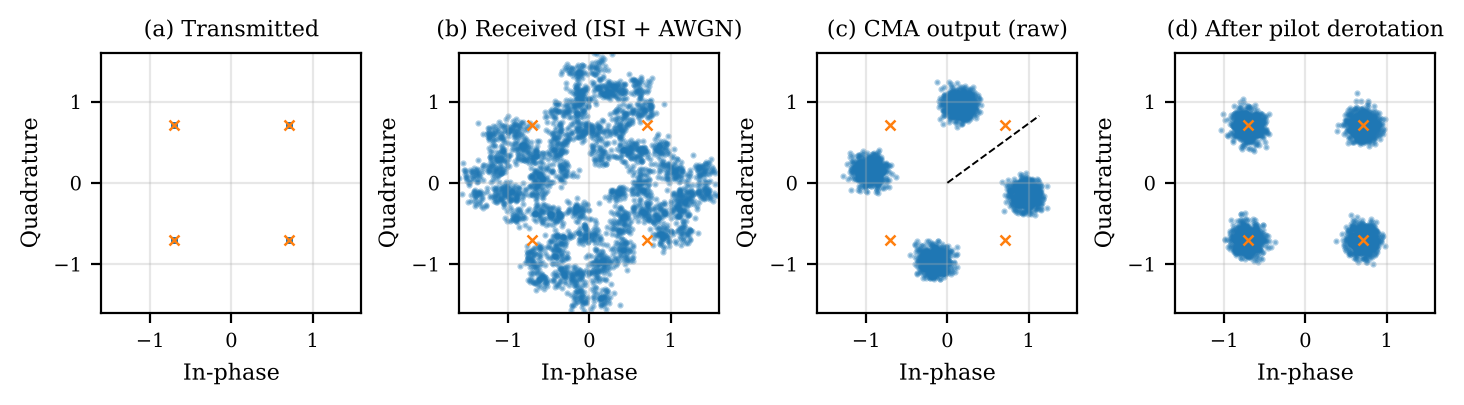

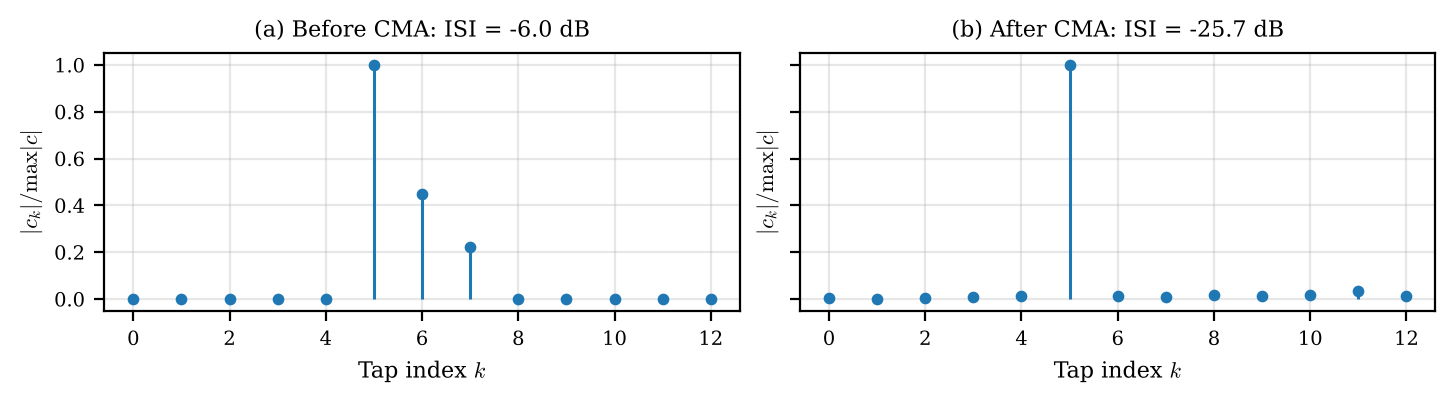

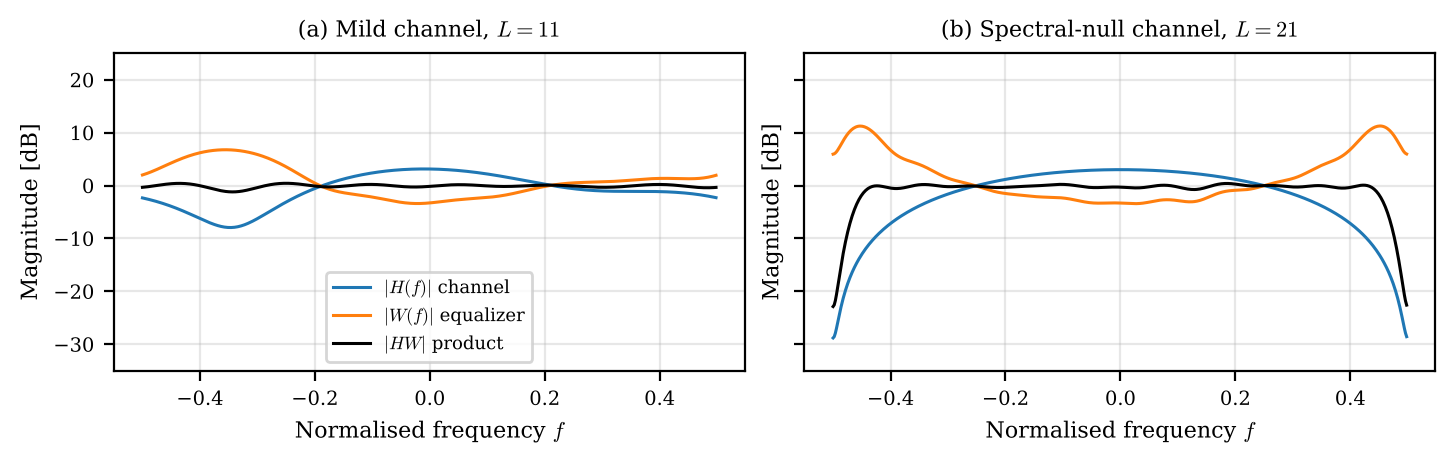

In [7]:
def exp_main_demo():
    print("E1/E2/E5 constellation, h*w, frequency response")
    rng = rng_for(1)
    phi = np.deg2rad(37)
    h = normalize_channel(H_MILD) * np.exp(1j * phi)          # static carrier-phase offset
    L, mu, snr = 11, 1e-3, 20
    o = pipeline("QPSK", h, snr, 1, 20000, 3000, L, mu, rng)
    pts = o["pts"]
    x2, y2, ya = o["x2"][0][50:], o["y2"][0][50:], o["ya"][0][50:]
    ph = np.degrees(np.angle(o["g"][0]))
    num("MainPhaseDeg", ph, "{:.0f}")
    fig, ax = plt.subplots(1, 4, figsize=(COL2, 2.0))
    scat(ax[0], gen_symbols("QPSK", (3000,), rng), "(a) Transmitted", pts=pts)
    scat(ax[1], x2, "(b) Received (ISI + AWGN)", pts=pts)
    scat(ax[2], y2, "(c) CMA output (raw)", pts=pts)
    scat(ax[3], ya, "(d) After pilot derotation", pts=pts)
    ax[2].plot([0, 1.4 * np.cos(np.radians(ph))], [0, 1.4 * np.sin(np.radians(ph))], "k--", lw=0.7)
    save(fig, "constellation_qpsk")

    # h*w stem plot
    w = o["w"]
    c_after = combined_response(h, w)[0]
    c0 = combined_response(h, np.eye(L)[None, L // 2])[0]
    isi0 = residual_isi(c0[None], db=True)[0]; isi1 = residual_isi(c_after[None], db=True)[0]
    num("ISIbefore", isi0); num("ISIafter", isi1)
    fig, ax = plt.subplots(1, 2, figsize=(COL2, 1.9), sharey=True)
    for a, c, t in [(ax[0], c0, f"(a) Before CMA: ISI = {isi0:.1f} dB"),
                    (ax[1], c_after, f"(b) After CMA: ISI = {isi1:.1f} dB")]:
        a.stem(np.arange(len(c)), np.abs(c) / np.abs(c).max(), basefmt=" ")
        a.set_title(t); a.set_xlabel("Tap index $k$"); a.set_ylabel(r"$|c_k|/\max|c|$")
    save(fig, "hw_stem")

    # frequency responses (mild and harsh)
    fig, ax = plt.subplots(1, 2, figsize=(COL2, 2.2), sharey=True)
    f = np.linspace(-0.5, 0.5, 512, endpoint=False)
    for a, hh, LL, mmu, Ntr, ttl in [(ax[0], normalize_channel(H_MILD), 11, 1e-3, 20000, "(a) Mild channel, $L=11$"),
                                     (ax[1], normalize_channel(H_HARSH), 21, 1e-3, 60000, "(b) Spectral-null channel, $L=21$")]:
        oo = pipeline("QPSK", hh, 25, 1, Ntr, 2000, LL, mmu, rng)
        E = lambda v: np.exp(-2j * np.pi * np.outer(f, np.arange(len(v)))) @ v
        Hf, Wf = E(hh), E(oo["w"][0])
        db = lambda v: 20 * np.log10(np.abs(v) + 1e-9)
        a.plot(f, db(Hf), label="$|H(f)|$ channel")
        a.plot(f, db(Wf), label="$|W(f)|$ equalizer")
        a.plot(f, db(Hf * Wf), "k", label="$|H W|$ product")
        a.set_title(ttl); a.set_xlabel("Normalised frequency $f$"); a.set_ylabel("Magnitude [dB]")
        a.set_ylim(-35, 25)
        flat = db(Hf * Wf)[np.abs(f) < 0.4]
        JSON[f"flat_ripple_{LL}"] = float(flat.max() - flat.min())
    ax[0].legend(loc="lower center", ncol=1)
    save(fig, "freq_response")
    num("RippleMild", JSON["flat_ripple_11"]); num("RippleHarsh", JSON["flat_ripple_21"])
    num("MinHHarsh", 20 * np.log10(np.abs(np.fft.fft(normalize_channel(H_HARSH), 512)).min()))

exp_main_demo()

### 4.2 Learning curve (E3)
Cost averaged over 100 runs (log axis) and median residual ISI of $h*w[n]$.

E3 learning curve


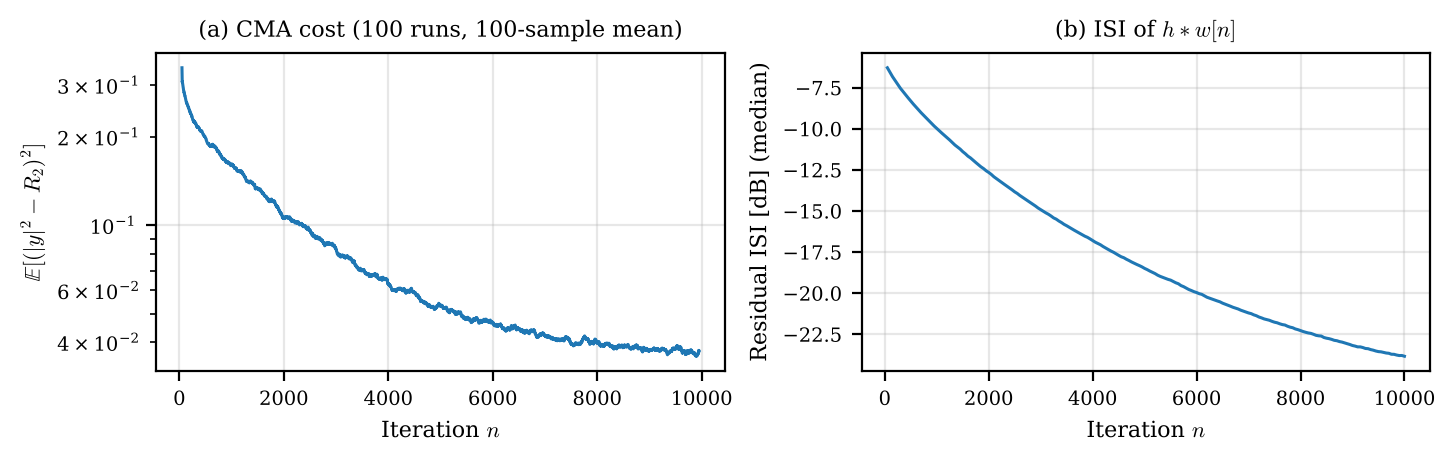

In [8]:
def exp_learning():
    print("E3 learning curve")
    R = 20 if QUICK else 100
    rng = rng_for(3)
    h = normalize_channel(H_MILD); L, mu, snr, N = 11, 1e-3, 20, 10000
    pts = constellation("QPSK"); R2 = cm_constant(pts)
    s = gen_symbols("QPSK", (R, N), rng); x = apply_channel(s, h, snr, rng)
    y, w, sn = cma_train(x, L, mu, R2, snap_every=50)
    J = (np.abs(y) ** 2 - R2) ** 2
    Jm = smooth(J.mean(0), 100)
    isi = np.median(dbc(isi_traj(h, sn)), axis=0)
    fig, ax = plt.subplots(1, 2, figsize=(COL2, 2.2))
    ax[0].semilogy(np.arange(len(Jm)) + 50, Jm)
    ax[0].set_xlabel("Iteration $n$"); ax[0].set_ylabel(r"$\mathbb{E}[(|y|^2-R_2)^2]$")
    ax[0].set_title(f"(a) CMA cost ({R} runs, 100-sample mean)")
    ax[1].plot((np.arange(len(isi)) + 1) * 50, isi)
    ax[1].set_xlabel("Iteration $n$"); ax[1].set_ylabel("Residual ISI [dB] (median)")
    ax[1].set_title("(b) ISI of $h*w[n]$")
    save(fig, "learning_curve")
    num("CostFloor", Jm[-2000:].mean(), "{:.3f}"); num("CostStart", J.mean(0)[:50].mean(), "{:.2f}")
    t15 = int(np.argmax(isi < -15)) * 50 + 50
    num("TconvMain", t15, "{:.0f}"); num("ISIfloorMain", isi[-40:].mean())
    num("RtwoQPSK", R2, "{:.2f}")

exp_learning()

### 4.3 Step-size sweep (E4)
Faster convergence vs. higher steady-state ISI; $\mu=0.1$ diverges.

E4 step-size sweep


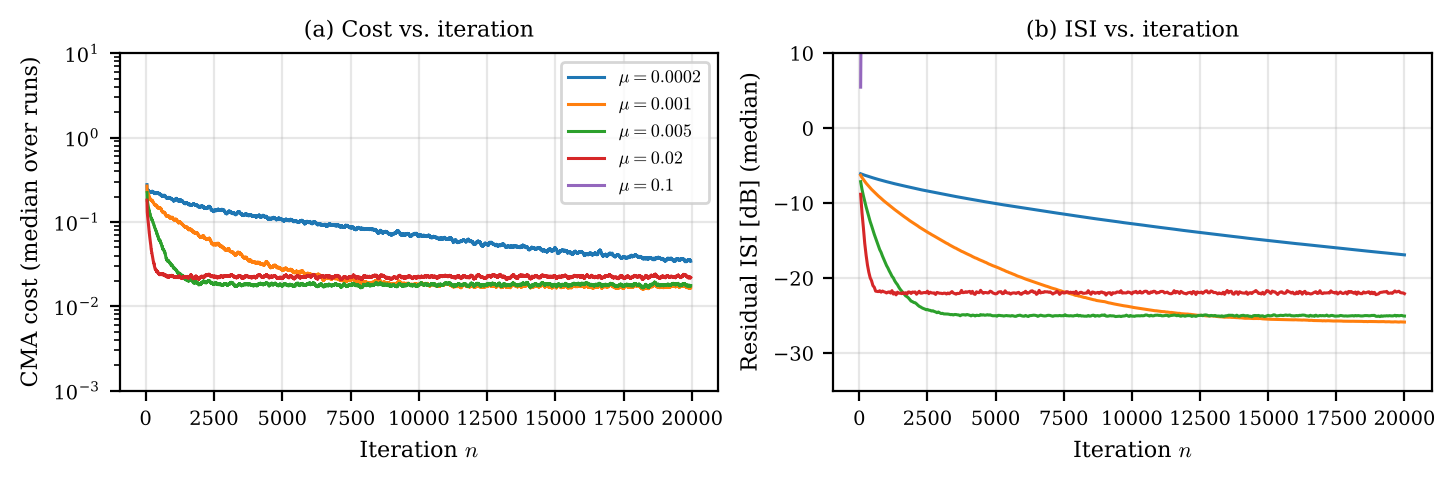

\begin{tabular}{lccc}
\toprule
$\mu$ & Iter. to $-15$\,dB & Steady ISI [dB] & Diverged [\%]\\
\midrule
0.0002 & 15100 & -16.2 & 0\\
0.001 & 3050 & -25.7 & 0\\
0.005 & 650 & -25.0 & 0\\
0.02 & 200 & -21.9 & 0\\
0.1 & -- & 30.0 & 100\\
\bottomrule
\end{tabular}


In [9]:
def exp_mu_sweep():
    print("E4 step-size sweep")
    R = 20 if QUICK else 100
    rng = rng_for(4)
    h = normalize_channel(H_MILD); L, snr, N = 11, 20, 20000
    pts = constellation("QPSK"); R2 = cm_constant(pts)
    mus = [2e-4, 1e-3, 5e-3, 2e-2, 1e-1]
    s = gen_symbols("QPSK", (R, N), rng); x = apply_channel(s, h, snr, rng)
    fig, ax = plt.subplots(1, 2, figsize=(COL2, 2.3))
    rows = []
    for mu in mus:
        y, w, sn = cma_train(x, L, mu, R2, snap_every=50)
        J = np.nan_to_num((np.abs(y) ** 2 - R2) ** 2, nan=1e3, posinf=1e3)
        Jm = smooth(np.median(J, 0), 100)
        isi = dbc(isi_traj(h, sn))
        med = np.median(isi, 0)
        fin = isi[:, -1]
        div = float(np.mean(fin > -3))
        t15 = (int(np.argmax(med < -15)) * 50 + 50) if (med < -15).any() else None
        ss = float(np.median(isi[:, -80:]))
        rows.append((mu, t15, ss, div))
        ax[0].semilogy(np.arange(len(Jm)) + 50, np.maximum(Jm, 1e-3), label=rf"$\mu={mu:g}$")
        ax[1].plot((np.arange(len(med)) + 1) * 50, med, label=rf"$\mu={mu:g}$")
    ax[0].set_xlabel("Iteration $n$"); ax[0].set_ylabel("CMA cost (median over runs)")
    ax[0].set_title("(a) Cost vs. iteration"); ax[0].set_ylim(1e-3, 1e1); ax[0].legend()
    ax[1].set_xlabel("Iteration $n$"); ax[1].set_ylabel("Residual ISI [dB] (median)")
    ax[1].set_title("(b) ISI vs. iteration"); ax[1].set_ylim(-35, 10)
    save(fig, "mu_sweep")
    JSON["mu_rows"] = rows
    lines = [r"\begin{tabular}{lccc}", r"\toprule",
             r"$\mu$ & Iter. to $-15$\,dB & Steady ISI [dB] & Diverged [\%]\\", r"\midrule"]
    for mu, t, ss, dv in rows:
        lines.append(rf"{mu:g} & {'--' if t is None else t} & {ss:.1f} & {100 * dv:.0f}\\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    TAB["mu"] = "\n".join(lines)

exp_mu_sweep()
print(TAB['mu'])

### 4.4 BER vs SNR (E6)
No equalizer vs CMA vs oracle MMSE vs AWGN bound $Q(\sqrt{E_s/N_0})$. Delay, gain and phase are resolved with pilots before counting errors.

E6 BER vs SNR


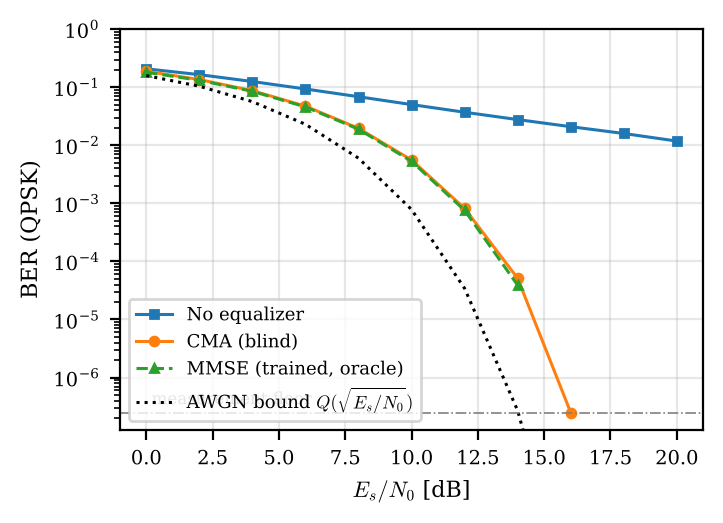

In [10]:
def ber_curves(h, L, mu, snrs, R, Ntr, Nte, rng, mod="QPSK"):
    res = {k: [] for k in ["noeq", "cma", "mmse"]}
    for snr in snrs:
        o = pipeline(mod, h, snr, R, Ntr, Nte, L, mu, rng, with_mmse=True)
        res["cma"].append(err_rate(mod, o["ya"], o["ref"]).mean())
        res["mmse"].append(err_rate(mod, o["yma"], o["refm"]).mean())
        y0, r0, _, _ = align(o["x2"], o["s2"], 0)
        res["noeq"].append(err_rate(mod, y0, r0).mean())
    return {k: np.array(v) for k, v in res.items()}


def exp_ber():
    print("E6 BER vs SNR")
    R, Nte = (6, 20000) if QUICK else (20, 100000)
    rng = rng_for(6)
    snrs = np.arange(0, 21, 2)
    h = normalize_channel(H_MILD)
    res = ber_curves(h, 11, 1e-3, snrs, R, 20000, Nte, rng)
    floor = 1 / (2 * R * Nte)
    th = qfunc(np.sqrt(10 ** (snrs / 10)))
    fig, ax = plt.subplots(figsize=(COL1, 2.5))
    ax.semilogy(snrs, nz(res["noeq"]), "s-", label="No equalizer")
    ax.semilogy(snrs, nz(res["cma"]), "o-", label="CMA (blind)")
    ax.semilogy(snrs, nz(res["mmse"]), "^--", label="MMSE (trained, oracle)")
    ax.semilogy(snrs, th, "k:", label=r"AWGN bound $Q(\sqrt{E_s/N_0})$")
    ax.axhline(floor, color="gray", lw=0.6, ls="-."); ax.text(0.2, floor * 1.4, "measurement floor", fontsize=6, color="gray")
    ax.set_ylim(floor / 2, 1); ax.set_xlabel(r"$E_s/N_0$ [dB]"); ax.set_ylabel("BER (QPSK)")
    ax.legend(loc="lower left")
    save(fig, "ber_vs_snr")
    k10 = list(snrs).index(10); k14 = list(snrs).index(14)
    num("BERnoeqTen", res["noeq"][k10], "{:.1e}"); num("BERcmaTen", res["cma"][k10], "{:.1e}")
    num("BERmmseTen", res["mmse"][k10], "{:.1e}"); num("BERthTen", th[k10], "{:.1e}")
    num("BERcmaFourteen", res["cma"][k14], "{:.1e}"); num("BERmmseFourteen", res["mmse"][k14], "{:.1e}")
    JSON["ber"] = {k: v.tolist() for k, v in res.items()}; JSON["ber_snr"] = snrs.tolist()
    # SNR needed for BER=1e-3 (linear interpolation in log domain)
    def snr_at(b, target=1e-3):
        b = np.maximum(b, 1e-9)
        return float(np.interp(np.log10(target), np.log10(b)[::-1], snrs[::-1]))
    num("SNRcmaMilli", snr_at(res["cma"])); num("SNRmmseMilli", snr_at(res["mmse"]))
    num("SNRthMilli", snr_at(th))

exp_ber()

### 4.5 Parameter studies (E7)
(a) taps, (b) initialisation / delay reached, (c) phase left by CMA, (d) spike position, (e) spectral-null channel, (f) SNR.

E7 parameter studies


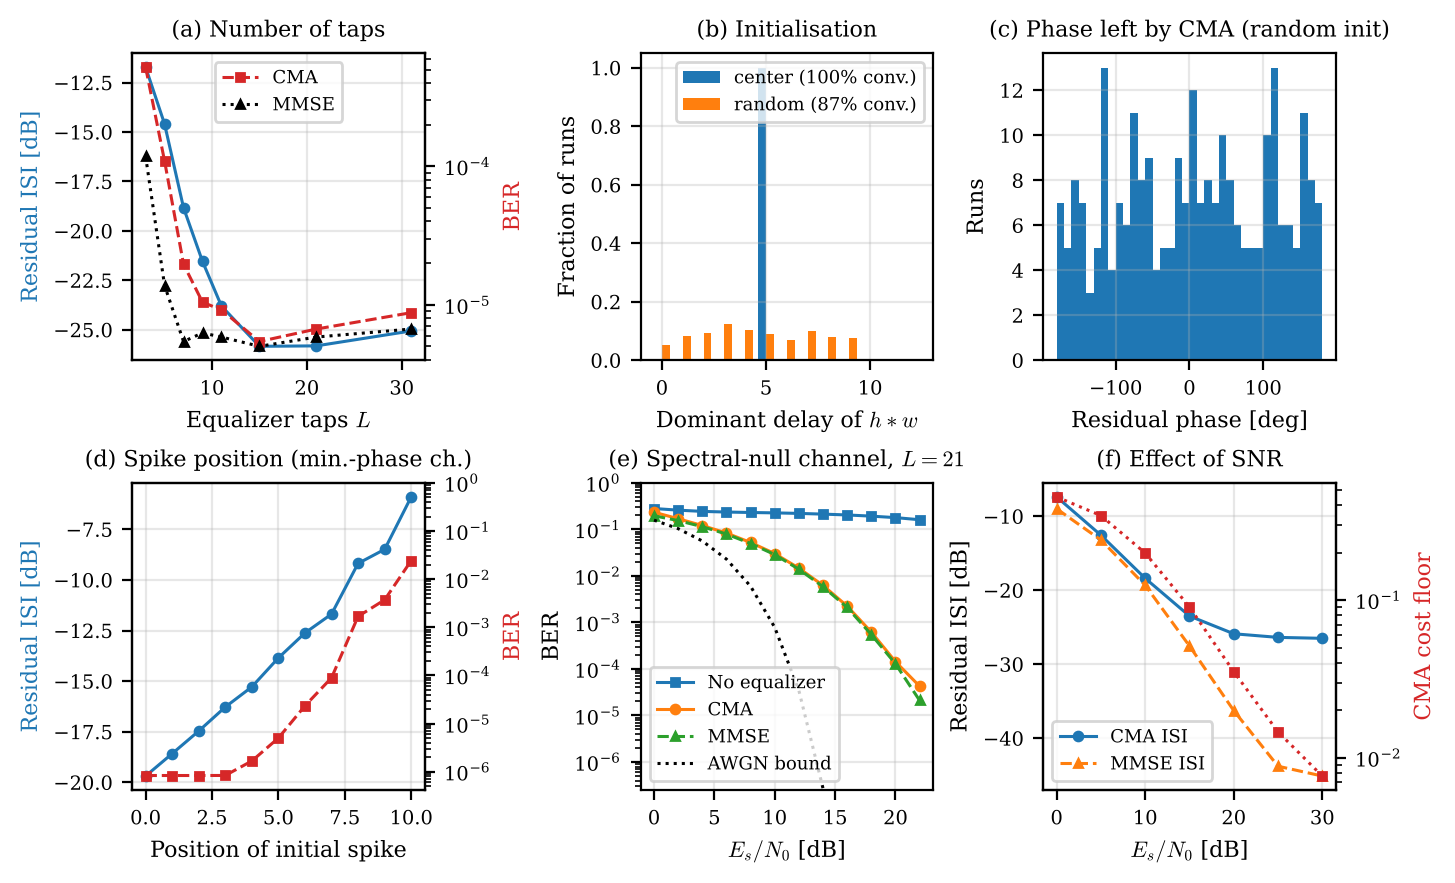

In [11]:
def exp_params():
    print("E7 parameter studies")
    R = 20 if QUICK else 60
    rng = rng_for(7)
    h = normalize_channel(H_MILD)
    fig, ax = plt.subplots(2, 3, figsize=(COL2, 4.3))

    # (a) number of taps
    Ls = [3, 5, 7, 9, 11, 15, 21, 31]
    isi_med, ber15, mmse_ber = [], [], []
    for L in Ls:
        o = pipeline("QPSK", h, 15, R, 30000, 20000, L, 1e-3, rng, with_mmse=True)
        isi_med.append(np.median(dbc(residual_isi(combined_response(h, o["w"])))))
        ber15.append(ber_qpsk(o["ya"], o["ref"]).mean()); mmse_ber.append(ber_qpsk(o["yma"], o["refm"]).mean())
    a = ax[0, 0]; a.plot(Ls, isi_med, "o-", color="C0"); a.set_xlabel("Equalizer taps $L$")
    a.set_ylabel("Residual ISI [dB]", color="C0"); a.set_title("(a) Number of taps")
    b = a.twinx(); b.grid(False)
    floor = 1 / (2 * R * 20000)
    b.semilogy(Ls, np.maximum(ber15, floor), "s--", color="C3", label="CMA")
    b.semilogy(Ls, np.maximum(mmse_ber, floor), "^:", color="k", label="MMSE")
    b.set_ylabel("BER", color="C3"); b.legend(loc="upper center")
    JSON["taps"] = dict(L=Ls, isi=isi_med, ber=ber15, ber_mmse=mmse_ber)
    TAB["taps"] = "\n".join([r"\begin{tabular}{lcccccccc}", r"\toprule",
        "$L$ & " + " & ".join(map(str, Ls)) + r"\\", r"\midrule",
        "ISI [dB] & " + " & ".join(f"{v:.1f}" for v in isi_med) + r"\\",
        "BER (CMA) & " + " & ".join(f"{v:.0e}" if v > 0 else "0" for v in ber15) + r"\\",
        r"\bottomrule", r"\end{tabular}"])

    # (b) initialisation
    inits = ["center", "first", "random", "zero"]
    Ri = 50 if QUICK else 300
    L = 11; pts = constellation("QPSK"); R2 = cm_constant(pts)
    s = gen_symbols("QPSK", (Ri, 20000), rng); x = apply_channel(s, h, 20, rng)
    succ, dly = {}, {}
    ph_rand = None
    for ini in inits:
        y, w = cma_train(x, L, 1e-3, R2, ini, rng)
        c = combined_response(h, w); isi = dbc(residual_isi(c))
        ok = isi < -10
        succ[ini] = float(ok.mean())
        dly[ini] = np.argmax(np.abs(c), axis=1)[ok]
        if ini == "random":
            ya, ref, d, g = align(apply_filter(x, w), s, L + 1)
            ph_rand = np.degrees(np.angle(g[ok]))
    a = ax[0, 1]
    ds = np.arange(0, L + 2)
    wbar = 0.38
    for j, ini in enumerate(["center", "random"]):
        cnt = np.array([(dly[ini] == d).sum() for d in ds]) / Ri
        a.bar(ds + (j - 0.5) * wbar, cnt, wbar, label=f"{ini} ({100 * succ[ini]:.0f}% conv.)")
    a.set_xlabel("Dominant delay of $h*w$"); a.set_ylabel("Fraction of runs")
    a.set_title("(b) Initialisation"); a.legend()
    JSON["init_success"] = succ
    TAB["init"] = "\n".join([r"\begin{tabular}{lcc}", r"\toprule",
        r"Init. & Converged [\%] & \# distinct delays\\", r"\midrule"] +
        [rf"{i} & {100 * succ[i]:.0f} & {len(np.unique(dly[i]))}\\" for i in inits] +
        [r"\bottomrule", r"\end{tabular}"])
    # (c) phase ambiguity histogram + spike position
    a = ax[0, 2]
    a.hist(ph_rand, bins=36, range=(-180, 180), color="C0")
    a.set_xlabel("Residual phase [deg]"); a.set_ylabel("Runs")
    a.set_title("(c) Phase left by CMA (random init)")
    num("PhaseSpread", float(np.std(((ph_rand + 45) % 90) - 45)), "{:.0f}")
    num("PhaseRuns", len(ph_rand), "{:.0f}")

    # spike-position study on a minimum-phase channel (energy early -> best delay near 0)
    hA = normalize_channel([1, 0.5 + 0.25j, 0.3 - 0.2j, 0.1j]); Rp = 20 if QUICK else 30
    sA = gen_symbols("QPSK", (Rp, 40000), rng); xA = apply_channel(sA, hA, 20, rng)
    sB = gen_symbols("QPSK", (Rp, 20000), rng); xB = apply_channel(sB, hA, 20, rng)
    wm, _ = mmse_ls(xA, sA, 11)
    bm = ber_qpsk(*align(apply_filter(xB, wm), sB, 13)[:2]).mean()
    bers, isis = [], []
    for pos in range(11):
        _, wA = cma_train(xA, 11, 1e-3, 1.0, w0=init_weights(Rp, 11, "center", center=pos))
        bers.append(ber_qpsk(*align(apply_filter(xB, wA), sB, 13)[:2]).mean())
        isis.append(np.median(dbc(residual_isi(combined_response(hA, wA)))))
    a = ax[1, 0]
    fl = 1 / (2 * Rp * 20000)
    a.plot(range(11), isis, "o-", color="C0"); a.set_xlabel("Position of initial spike")
    a.set_ylabel("Residual ISI [dB]", color="C0"); a.set_title("(d) Spike position (min.-phase ch.)")
    b = a.twinx(); b.grid(False)
    b.semilogy(range(11), np.maximum(bers, fl), "s--", color="C3"); b.set_ylabel("BER", color="C3")
    b.set_ylim(fl / 2, 1)
    JSON["spike_pos"] = dict(ber=bers, isi=isis, mmse=float(bm))
    num("SpikeIsiZero", isis[0]); num("SpikeIsiCenter", isis[5]); num("SpikeIsiEnd", isis[10])

    # (c) harsh channel BER
    hh = normalize_channel(H_HARSH)
    snrs = np.arange(0, 23, 2)
    Rh, Nte = (6, 20000) if QUICK else (20, 50000)
    res = ber_curves(hh, 21, 1e-3, snrs, Rh, 60000, Nte, rng)
    floor = 1 / (2 * Rh * Nte); a = ax[1, 1]
    a.semilogy(snrs, nz(res["noeq"]), "s-", label="No equalizer")
    a.semilogy(snrs, nz(res["cma"]), "o-", label="CMA")
    a.semilogy(snrs, nz(res["mmse"]), "^--", label="MMSE")
    a.semilogy(snrs, qfunc(np.sqrt(10 ** (snrs / 10))), "k:", label="AWGN bound")
    a.set_ylim(floor / 2, 1); a.set_xlabel(r"$E_s/N_0$ [dB]"); a.set_ylabel("BER")
    a.set_title("(e) Spectral-null channel, $L=21$"); a.legend(loc="lower left")
    JSON["harsh"] = {k: v.tolist() for k, v in res.items()}
    k = list(snrs).index(14)
    num("HarshNoeq", res["noeq"][k], "{:.1e}"); num("HarshCma", res["cma"][k], "{:.1e}")
    num("HarshMmse", res["mmse"][k], "{:.1e}")

    # (d) steady-state ISI vs SNR
    snr_list = [0, 5, 10, 15, 20, 25, 30]
    isi_c, isi_m, j_floor = [], [], []
    pts = constellation("QPSK")
    for sn in snr_list:
        o = pipeline("QPSK", h, sn, R, 20000, 2000, 11, 1e-3, rng, with_mmse=True)
        isi_c.append(np.median(dbc(residual_isi(combined_response(h, o["w"])))))
        isi_m.append(np.median(dbc(residual_isi(combined_response(h, o["wm"])))))
        j_floor.append(np.median(((np.abs(o["y"][:, -3000:]) ** 2 - 1) ** 2).mean(1)))
    a = ax[1, 2]
    a.plot(snr_list, isi_c, "o-", label="CMA ISI"); a.plot(snr_list, isi_m, "^--", label="MMSE ISI")
    a.set_xlabel(r"$E_s/N_0$ [dB]"); a.set_ylabel("Residual ISI [dB]")
    a.set_title("(f) Effect of SNR"); a.legend(loc="lower left")
    b = a.twinx(); b.grid(False)
    b.semilogy(snr_list, j_floor, "s:", color="C3"); b.set_ylabel("CMA cost floor", color="C3")
    JSON["snr_study"] = dict(snr=snr_list, isi_cma=isi_c, isi_mmse=isi_m, cost_floor=j_floor)
    save(fig, "param_studies")

exp_params()

### 4.6 16-QAM / 64-QAM: CMA alone vs CMA + DD-LMS (E8)
Non-constant modulus: CMA opens the eye only partly; a decision-directed stage after a short pilot gain/phase fix repairs most of the loss.

E8 high-order QAM: CMA alone vs CMA -> DD-LMS


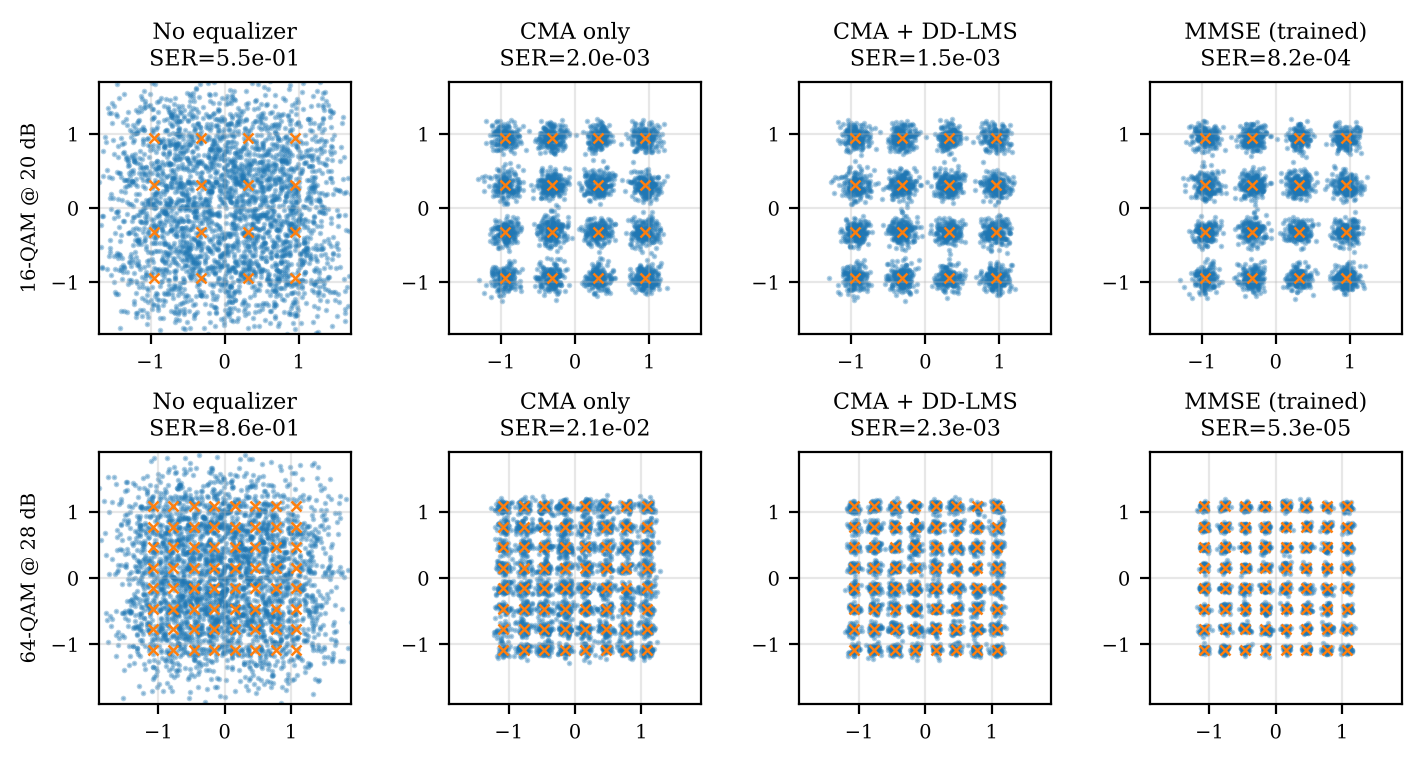

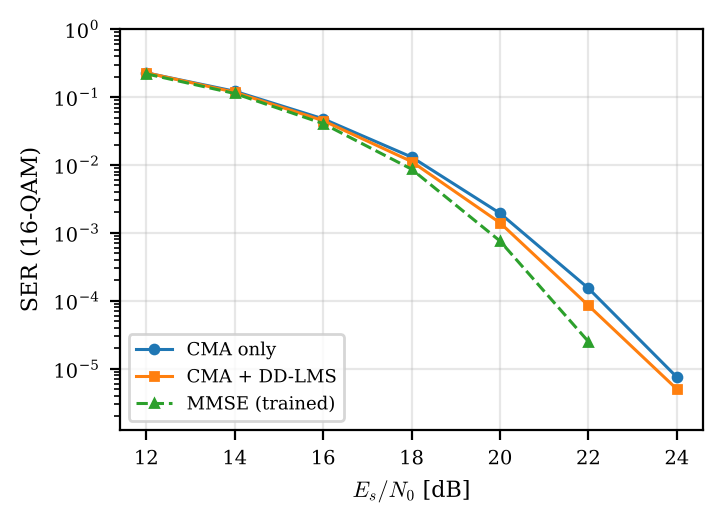

In [12]:
def cma_dd_chain(mod, h, snr, R, L, mu_cma, mu_dd, rng, Ntr=60000, Ndd=40000, Nte=20000, npil=2000):
    """CMA -> pilot gain/phase fix (npil symbols) -> decision-directed LMS; returns dict of SERs."""
    pts = constellation(mod); R2 = cm_constant(pts); M = len(h)
    s = gen_symbols(mod, (R, Ntr), rng); x = apply_channel(s, h, snr, rng)
    y, w = cma_train(x, L, mu_cma, R2)
    _, _, _, g = align(y[:, -npil - 200:], s[:, -npil - 200:], L + M - 2, skip=100)
    s3 = gen_symbols(mod, (R, Ndd), rng); x3 = apply_channel(s3, h, snr, rng)
    _, wdd = dd_lms_train(x3, pts, L, mu_dd, w / g[:, None])
    wm, _ = mmse_ls(x, s, L)
    s2 = gen_symbols(mod, (R, Nte), rng); x2 = apply_channel(s2, h, snr, rng)
    out = {}
    for name, ww in [("cma", w), ("dd", wdd), ("mmse", wm)]:
        ya, ref, _, _ = align(apply_filter(x2, ww), s2, L + M - 2)
        out[name] = (ya, ref, ser(ya, ref, pts).mean())
    y0, r0, _, _ = align(x2, s2, 0)
    out["noeq"] = (y0, r0, ser(y0, r0, pts).mean())
    return out


def exp_qam():
    print("E8 high-order QAM: CMA alone vs CMA -> DD-LMS")
    rng = rng_for(8)
    h = normalize_channel(H_MILD) * np.exp(1j * np.deg2rad(25))
    L = 11; R = 6 if QUICK else 30
    cases = [("16-QAM", 20, 5e-4, 1e-3), ("64-QAM", 28, 2e-4, 1e-3)]
    fig, ax = plt.subplots(2, 4, figsize=(COL2, 3.7))
    for r, (mod, snr, mc, md) in enumerate(cases):
        o = cma_dd_chain(mod, h, snr, R, L, mc, md, rng)
        pts = constellation(mod)
        tag = "Sixteen" if mod == "16-QAM" else "SixtyFour"
        for k, v in o.items():
            num("SER" + tag + dict(cma="CMA", dd="DD", mmse="MMSE", noeq="Noeq")[k], v[2], "{:.1e}")
        for a, (k, t) in zip(ax[r], [("noeq", "No equalizer"), ("cma", "CMA only"),
                                    ("dd", "CMA + DD-LMS"), ("mmse", "MMSE (trained)")]):
            scat(a, o[k][0][0][-3000:], f"{t}\nSER={o[k][2]:.1e}", lim=1.7 if r == 0 else 1.9, pts=pts, s=1)
            a.set_xlabel(""); a.set_ylabel("")
        ax[r, 0].set_ylabel(f"{mod} @ {snr} dB", fontsize=7)
    save(fig, "qam_dd")

    # SER vs SNR for 16-QAM
    snrs = np.arange(12, 27, 2); Rs = 6 if QUICK else 20
    acc = {k: [] for k in ["cma", "dd", "mmse"]}
    for snr in snrs:
        o = cma_dd_chain("16-QAM", h, snr, Rs, L, 5e-4, 1e-3, rng, Ntr=40000, Ndd=30000, Nte=20000)
        for k in acc: acc[k].append(o[k][2])
    fl = 1 / (Rs * 20000)
    fig, a = plt.subplots(figsize=(COL1, 2.5))
    a.semilogy(snrs, nz(acc["cma"]), "o-", label="CMA only")
    a.semilogy(snrs, nz(acc["dd"]), "s-", label="CMA + DD-LMS")
    a.semilogy(snrs, nz(acc["mmse"]), "^--", label="MMSE (trained)")
    a.set_xlabel(r"$E_s/N_0$ [dB]"); a.set_ylabel("SER (16-QAM)"); a.set_ylim(fl / 2, 1); a.legend(loc="lower left")
    save(fig, "ser_16qam")
    JSON["ser16"] = dict(snr=snrs.tolist(), **{k: list(map(float, v)) for k, v in acc.items()})
    num("PilotLen", 2000, "{:.0f}")

exp_qam()

### 4.7 Modulation comparison (E10)
BPSK, QPSK, 8-PSK, 16-QAM, 64-QAM at 25 dB.

E10 modulation comparison


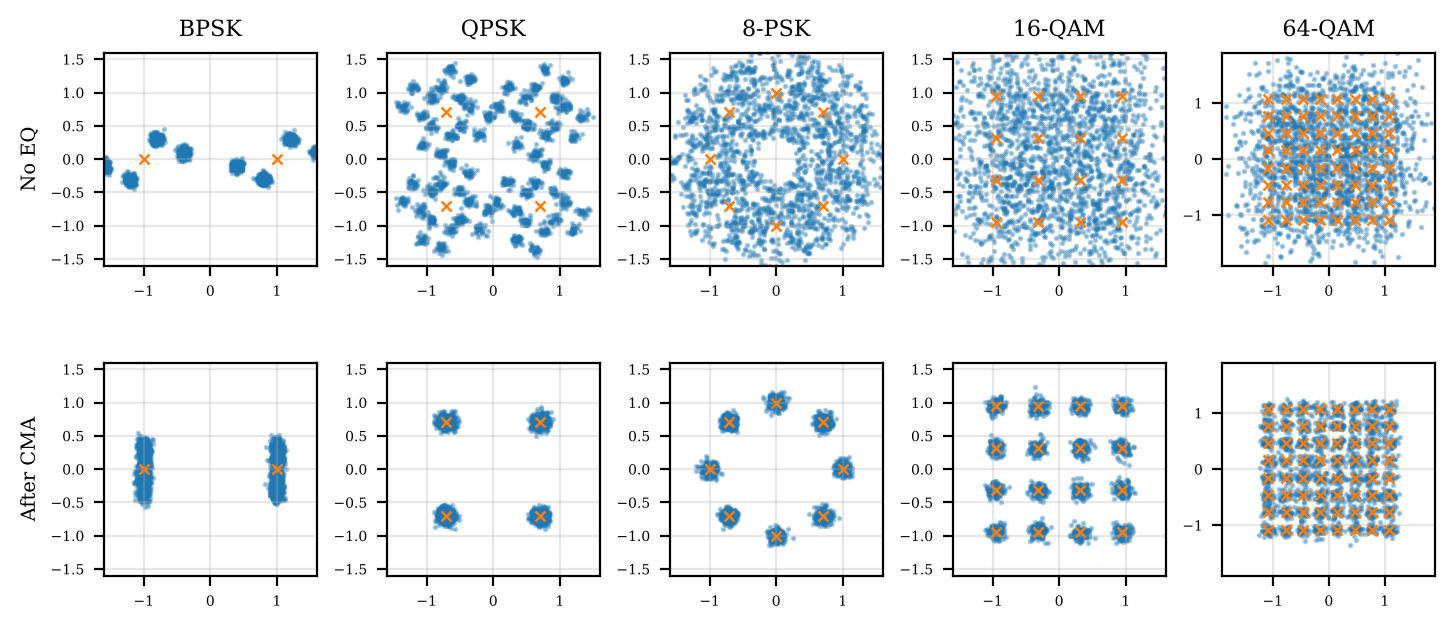

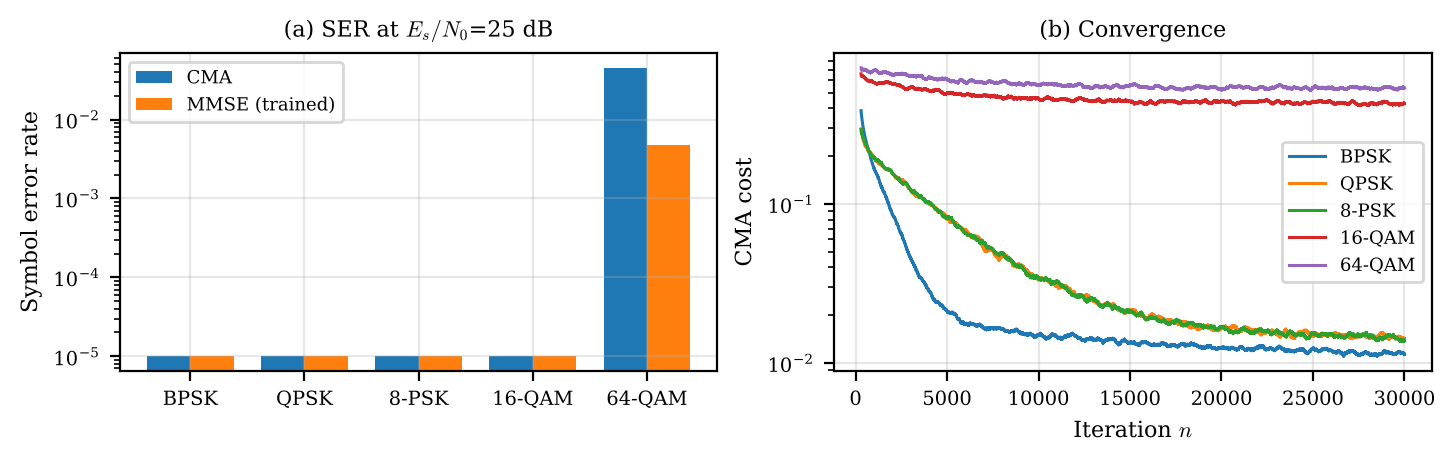

In [13]:
def exp_modulations():
    print("E10 modulation comparison")
    rng = rng_for(10)
    h = normalize_channel(H_MILD) * np.exp(1j * np.deg2rad(25))
    mods = ["BPSK", "QPSK", "8-PSK", "16-QAM", "64-QAM"]
    R = 4 if QUICK else 20
    L, snr, mu = 11, 25, 5e-4
    sers_c, sers_m, curves = [], [], []
    fig, ax = plt.subplots(2, 5, figsize=(COL2, 3.1))
    for j, mod in enumerate(mods):
        o = pipeline(mod, h, snr, R, 30000, 10000, L, mu, rng, with_mmse=True)
        sers_c.append(ser(o["ya"], o["ref"], o["pts"]).mean())
        sers_m.append(ser(o["yma"], o["refm"], o["pts"]).mean())
        J = (np.abs(o["y"]) ** 2 - o["R2"]) ** 2
        curves.append(smooth(J.mean(0), 300))
        xr, _, _, _ = align(o["x2"][:1], o["s2"][:1], 0)
        lim = 1.9 if "64" in mod else 1.6
        scat(ax[0, j], xr[0][-2000:], f"{mod}", lim=lim, pts=o["pts"], s=1)
        scat(ax[1, j], o["ya"][0][-2000:], "", lim=lim, pts=o["pts"], s=1)
        for a in ax[:, j]:
            a.set_xlabel(""); a.set_ylabel("")
            a.tick_params(labelsize=5)
    ax[0, 0].set_ylabel("No EQ", fontsize=7); ax[1, 0].set_ylabel("After CMA", fontsize=7)
    save(fig, "modulation_gallery")
    fig, ax = plt.subplots(1, 2, figsize=(COL2, 2.2))
    xx = np.arange(len(mods)); wb = 0.38
    ax[0].bar(xx - wb / 2, np.maximum(sers_c, 1e-5), wb, label="CMA")
    ax[0].bar(xx + wb / 2, np.maximum(sers_m, 1e-5), wb, label="MMSE (trained)")
    ax[0].set_yscale("log"); ax[0].set_xticks(xx); ax[0].set_xticklabels(mods)
    ax[0].set_ylabel("Symbol error rate"); ax[0].set_title(f"(a) SER at $E_s/N_0$={snr} dB"); ax[0].legend()
    for mod, c in zip(mods, curves):
        ax[1].semilogy(np.arange(len(c)) + 300, c, label=mod)
    ax[1].set_xlabel("Iteration $n$"); ax[1].set_ylabel("CMA cost"); ax[1].set_title("(b) Convergence"); ax[1].legend()
    save(fig, "modulation_compare")
    JSON["mod_ser_cma"] = dict(zip(mods, map(float, sers_c)))
    JSON["mod_ser_mmse"] = dict(zip(mods, map(float, sers_m)))
    TAB["mods"] = "\n".join([r"\begin{tabular}{lccccc}", r"\toprule", "& " + " & ".join(mods) + r"\\", r"\midrule",
        "CMA SER & " + " & ".join(f"{v:.1e}" if v > 0 else "0" for v in sers_c) + r"\\",
        "MMSE SER & " + " & ".join(f"{v:.1e}" if v > 0 else "0" for v in sers_m) + r"\\",
        r"\bottomrule", r"\end{tabular}"])

exp_modulations()

### 4.8 LMS (trained) vs CMA (blind) (E9)
Same spike initialisation; LMS uses training symbols.

E9 LMS vs CMA


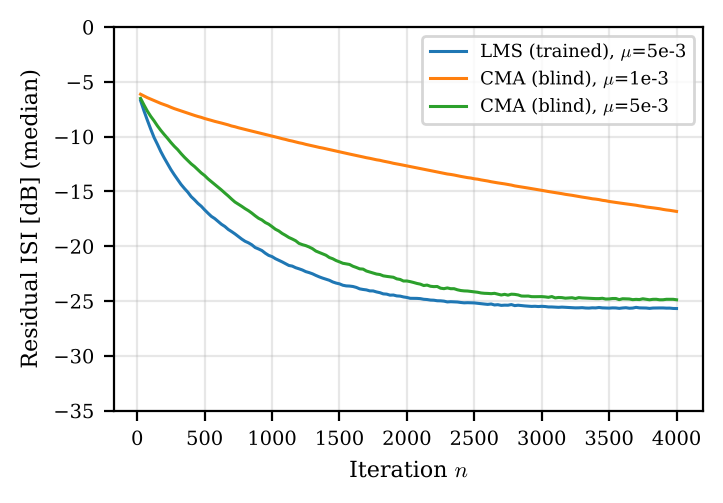

In [14]:
def exp_lms():
    print("E9 LMS vs CMA")
    R = 20 if QUICK else 100
    rng = rng_for(9)
    h = normalize_channel(H_MILD); L, snr, N = 11, 20, 4000
    pts = constellation("QPSK"); R2 = cm_constant(pts)
    s = gen_symbols("QPSK", (R, N), rng); x = apply_channel(s, h, snr, rng)
    fig, ax = plt.subplots(figsize=(COL1, 2.4))
    rows = {}
    for name, fn in [("LMS (trained), $\\mu$=5e-3", lambda: lms_train(x, s, L, 5e-3, L // 2, 25)),
                     ("CMA (blind), $\\mu$=1e-3", lambda: cma_train(x, L, 1e-3, R2, snap_every=25)),
                     ("CMA (blind), $\\mu$=5e-3", lambda: cma_train(x, L, 5e-3, R2, snap_every=25))]:
        sn = fn()[-1]
        med = np.median(dbc(isi_traj(h, sn)), 0)
        ax.plot((np.arange(len(med)) + 1) * 25, med, label=name)
        rows[name] = (int(np.argmax(med < -15)) * 25 + 25 if (med < -15).any() else None, float(med[-20:].mean()))
    ax.set_xlabel("Iteration $n$"); ax.set_ylabel("Residual ISI [dB] (median)")
    ax.set_ylim(-35, 0); ax.legend()
    save(fig, "lms_vs_cma")
    ks = list(rows)
    num("LMSiter", rows[ks[0]][0] or 0, "{:.0f}"); num("CMAiterSlow", rows[ks[1]][0] or 0, "{:.0f}")
    num("CMAiterFast", rows[ks[2]][0] or 0, "{:.0f}")
    num("LMSfloor", rows[ks[0]][1]); num("CMAfloorSlow", rows[ks[1]][1]); num("CMAfloorFast", rows[ks[2]][1])

exp_lms()

## 5. Results summary (generated)

In [15]:
def derive_numbers():
    """Closed-form constants and values pulled from the JSON dump (so the report never hand-types numbers)."""
    for tag, mod in [("QPSK", "QPSK"), ("Sixteen", "16-QAM"), ("SixtyFour", "64-QAM")]:
        r2 = cm_constant(constellation(mod))
        num("Rtwo" + tag, r2, "{:.3f}"); num("Jmin" + tag, r2 * (r2 - 1), "{:.3f}")
    tp = JSON["taps"]; Ls = tp["L"]
    for L, nm in [(3, "Three"), (5, "Five"), (11, "Eleven"), (15, "Fifteen"), (31, "ThirtyOne")]:
        i = Ls.index(L); num("TapsIsi" + nm, tp["isi"][i]); num("TapsBer" + nm, tp["ber"][i], "{:.0e}")
    ss = JSON["snr_study"]
    num("SnrCmaZero", ss["isi_cma"][0]); num("SnrCmaThirty", ss["isi_cma"][-1]); num("SnrMmseThirty", ss["isi_mmse"][-1])
    num("CostFloorThirty", ss["cost_floor"][-1], "{:.3f}"); num("CostFloorTen", ss["cost_floor"][2], "{:.3f}")


def write_outputs():
    derive_numbers()
    with open(RES / "numbers.tex", "w") as f:
        f.write("% auto-generated by experiments/run_all.py -- do not edit\n")
        for k, v in NUM.items():
            f.write(f"\\newcommand{{\\{k}}}{{{v}}}\n")
    with open(RES / "tables.tex", "w") as f:
        for k, v in TAB.items():
            f.write(f"% ---- {k}\n\\newcommand{{\\table{k}}}{{%\n{v}}}\n")
    with open(RES / "results.json", "w") as f:
        json.dump(JSON, f, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))

derive_numbers()
write_outputs()                       # results/results.json, numbers.tex, tables.tex for the LaTeX report
import re as _re
def _plain(s):
    s = _re.sub(r"\\ensuremath\{(.*)\}", r"\1", s)
    return s.replace("\\times 10^", "e").replace("{", "").replace("}", "")
print(f"{'quantity':<22}value")
for k, v in NUM.items():
    print(f"{k:<22}{_plain(v)}")

quantity              value
MainPhaseDeg          36
ISIbefore             -6.0
ISIafter              -25.7
RippleMild            1.6
RippleHarsh           1.1
MinHHarsh             -28.8
CostFloor             0.038
CostStart             0.39
TconvMain             3050
ISIfloorMain          -23.1
RtwoQPSK              1.000
BERnoeqTen            5.0e-2
BERcmaTen             5.6e-3
BERmmseTen            5.3e-3
BERthTen              7.8e-4
BERcmaFourteen        5.1e-5
BERmmseFourteen       3.9e-5
SNRcmaMilli           11.8
SNRmmseMilli          11.7
SNRthMilli            9.8
PhaseSpread           25
PhaseRuns             262
SpikeIsiZero          -19.7
SpikeIsiCenter        -13.8
SpikeIsiEnd           -5.9
HarshNoeq             2.1e-1
HarshCma              6.3e-3
HarshMmse             5.9e-3
SERSixteenCMA         2.0e-3
SERSixteenDD          1.5e-3
SERSixteenMMSE        8.2e-4
SERSixteenNoeq        5.5e-1
SERSixtyFourCMA       2.1e-2
SERSixtyFourDD        2.3e-3
SERSixtyFourMMSE      5.3

**Reading the numbers (mild channel, QPSK, 20 dB unless stated)**
* ISI: `ISIbefore` → `ISIafter` (dB). BER of CMA ≈ trained MMSE; both ≈ 2 dB from the AWGN bound at BER $10^{-3}$ (`SNRcmaMilli`, `SNRmmseMilli`, `SNRthMilli`).
* `LMSiter` vs `CMAiterFast`: iterations to reach −15 dB ISI (trained vs blind, same μ).
* `SERSixtyFourCMA` vs `SERSixtyFourDD`: CMA alone vs CMA + DD-LMS on 64-QAM.
* `Jmin*`: cost at the ideal point, $R_2(R_2-1)$.

## 6. Viva notes
1. **Phase ambiguity** — $J$ depends on $|y|$ only; $J(e^{j\theta}\mathbf w)=J(\mathbf w)$. Resolve with pilot / Costas / DD.
2. **Delay ambiguity** — i.i.d. symbols; shifting $\mathbf c$ does not change $J$.
3. **$R_2$** — makes the unit-gain ideal output stationary w.r.t. gain.
4. **Gradient** — $\nabla_{\mathbf w^*}J=2\mathbb E[(|y|^2-R_2)y\mathbf u^*]$ (checked against finite differences in the unit tests).
5. **Centre-spike init** — one dominant tap, open eye, stays in the intended basin; fixes delay ≈ $L/2$ (which can be suboptimal, see spike-position study). $\mathbf w=0$ is stationary.
6. **QAM** — non-constant modulus ⇒ $J_{\min}>0$ ⇒ gradient noise at the solution; add DD-LMS.
7. **BPSK output smeared vertically** — only radial deviation is penalised, tangential noise is not.
8. **μ trade-off** — speed vs steady-state ISI; too large diverges.
9. **Limitations** — $T$-spaced, ideal timing, static channel, oracle MMSE reference, pilot-aided alignment.

**AI-usage note.** AI helped draft code, report and slides; all outputs were checked by running the tests and inspecting every figure. Keep your own `AI_LOG.md` entries (prompts + how you verified) at each Git commit, as the course requires. The LaTeX report and Beamer slides are separate deliverables (they `\input` the `results/*.tex` files this notebook writes).